In [92]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

In [ ]:
df = pd.read_csv("placement.csv")

In [94]:
print(df.shape)
df.head(5)
df.drop("Unnamed: 0",axis=1,inplace = True)

(100, 4)


C:\Users\shada\AppData\Local\Temp\ipykernel_18568\1124807910.py:3: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop("Unnamed: 0",axis=1,inplace = True)


<Axes: xlabel='cgpa', ylabel='iq'>

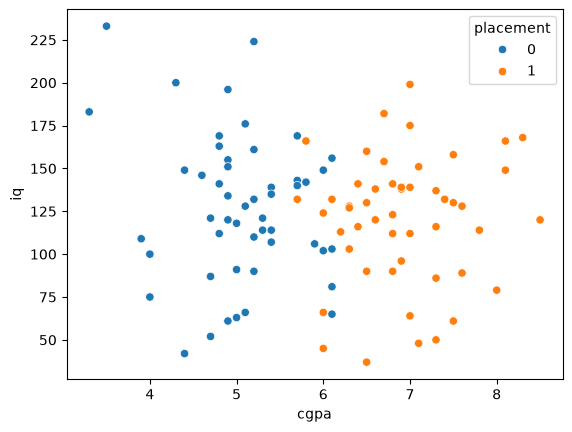

In [95]:
sns.scatterplot(data=df, x='cgpa', y='iq', hue='placement')

In [96]:
X = df.iloc[:,0:2]
y = df.iloc[:,-1]


In [97]:
X

,cgpa,iq
0,6.8,123.0
1,5.9,106.0
2,5.3,121.0
3,7.4,132.0
4,5.8,142.0
...,...,...
95,4.3,200.0
96,4.4,42.0
97,6.7,182.0
98,6.3,103.0


In [98]:
y

0     1
1     0
2     0
3     1
4     0
     ..
95    0
96    0
97    1
98    1
99    1
Name: placement, Length: 100, dtype: int64

In [107]:
from sklearn.linear_model import Perceptron
P = Perceptron(eta0=0.0001, penalty='l1',alpha=0.0001, max_iter=500, random_state=42)

In [108]:
P.fit(X,y)

,"penalty penalty: {'l2','l1','elasticnet'}, default=NoneThe penalty (aka regularization term) to be used.",'l1'
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method... versionadded:: 0.19",500
,"eta0 eta0: float, default=1Constant by which the updates are multiplied.",0.0001
,"random_state random_state: int, RandomState instance or None, default=0Used to shuffle the training data, when ``shuffle`` is set to``True``. Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term if regularization isused.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with `0 <= l1_ratio <= 1`.`l1_ratio=0` corresponds to L2 penalty, `l1_ratio=1` to L1.Only used if `penalty='elasticnet'`... versionadded:: 0.24",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, the iterations will stopwhen (loss > previous_loss - tol)... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.",0
,"n_jobs n_jobs: int, default=NoneThe number of CPUs to use to do the OVA (One Versus All, formulti-class problems) computation.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None


In [109]:
P.coef_

array([[ 0.04363, -0.00839]])

In [110]:
P.intercept_

array([0.0002])

In [111]:
from mlxtend.plotting import plot_decision_regions

d:\IT\Project\Deep_Learning_Practicals\env\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but Perceptron was fitted with feature names
  warnings.warn(


<Axes: >

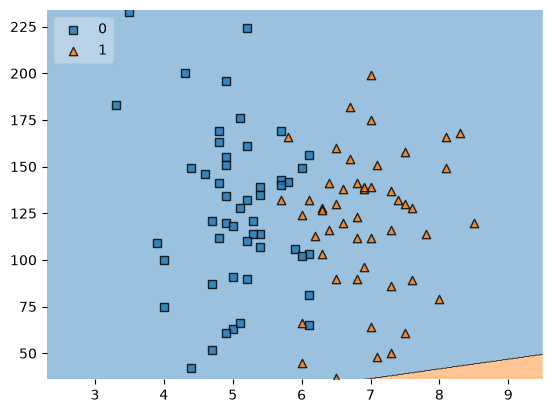

In [112]:
plot_decision_regions(X.values,y.values,clf=P,legend=2)

In [105]:
from sklearn.model_selection import train_test_split

# Assuming X contains your features and y contains your target labels
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)


In [106]:
from sklearn.linear_model import Perceptron
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# 1. Wrap StandardScaler and Perceptron in a Pipeline
# Scaling prevents IQ from dominating CGPA during gradient updates
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('perceptron', Perceptron(random_state=42))
])

# 2. Define the hyperparameter grid for Perceptron
param_grid = {
    'perceptron__penalty': [None, 'l2', 'l1', 'elasticnet'],
    'perceptron__alpha': [0.0001, 0.001, 0.01, 0.1],
    'perceptron__eta0': [0.0001, 0.001, 0.01, 0.1, 1.0],
    'perceptron__max_iter': [500, 1000, 2000],
    'perceptron__tol': [1e-3, 1e-4, None],
    'perceptron__class_weight': [None, 'balanced']
}

# 3. Configure GridSearchCV
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

# 4. Fit on your training data
grid_search.fit(X_train, y_train)

# 5. Print results
print("Best Hyperparameters:", grid_search.best_params_)
print(f"Best CV Accuracy: {grid_search.best_score_:.4f}")

# Evaluate on the unseen test set
best_perceptron = grid_search.best_estimator_
print(f"Test Set Accuracy: {best_perceptron.score(X_test, y_test):.4f}")

Best Hyperparameters: {'perceptron__alpha': 0.0001, 'perceptron__class_weight': None, 'perceptron__eta0': 0.0001, 'perceptron__max_iter': 500, 'perceptron__penalty': 'l1', 'perceptron__tol': None}
Best CV Accuracy: 0.9625
Test Set Accuracy: 0.9500
